In [9]:
import sys, os
print(sys.executable)   # which Python is running
print(os.getcwd())      # where it's looking
print(sys.path[:3])

/Users/mayastange/miniforge3/envs/advanced-python_course/bin/python
/Users/mayastange/Documents/Mayasim/tutorials
['/Users/mayastange/miniforge3/envs/advanced-python_course/lib/python310.zip', '/Users/mayastange/miniforge3/envs/advanced-python_course/lib/python3.10', '/Users/mayastange/miniforge3/envs/advanced-python_course/lib/python3.10/lib-dynload']


# 📦 Package import and fasta reading

In [ ]:
import Mayasim as ms


proteins = ms.read_fasta("../data/sample_proteins.fasta")
print(len(proteins))
print(proteins)

3
{'P11802': 'MATSRYEPVAEIGVGAYGTVYKARDPHSGHFVALKSVRVPNGGGGGGGLPISTVREVALLRRLEAFEHPNVVRLMDVCATSRTDREIKVTLVFEHVDQDLRTYLDKAPPPGLPAETIKDLMRQFLRGLDFLHANCIVHRDLKPENILVTSGGTVKLADFGLARIYSYQMALTPVVVTLWYRAPEVLLQSTYATPVDMWSVGCIFAEMFRRKPLFCGNSEADQLGKIFDLIGLPPEDDWPRDVSLPRGAFPPRGPRPVQSVVPEMEESGAQLLLEMLTFNPHKRISAFRALQHSYLHKDEGNPE', 'A0A087WTH1': 'MEDEEKAVEILGNTEAAHPPSPIRCCWLRLRCLAATSIICGCSCLGVMALVFAIKAEERHKAGRSEEAVRWGARARKLILASFAVWLAVLILGPLLLWLLSYAIAQAPEPTIDERE', 'A0A087WTH5': 'MVIEWERPRMILSNTTAVTPFLTKLWQETVQQGGNMSGLARRSPRSGDGKLEALYVLMVLGFFGFFTLGIMLSYIRSKKLEHSNDPFNVYIESNAWQEKDKAYVQARVLESYRSCYVVENHLAIEQPNTHLPETKPSP'}


# ✂️ Protein digestion using a protease

Digest the protein sequence dictionary with 'ms.digest_protein_collection' using a protease of your choice.

In [11]:
peptides = ms.digest_protein_collection(proteins, ms.enzyme_cleavage_patterns['LysC'])

print(peptides)

{'P11802': ['MATSRYEPVAEIGVGAYGTVYK', 'ARDPHSGHFVALK', 'VTLVFEHVDQDLRTYLDK', 'APPPGLPAETIK', 'DLMRQFLRGLDFLHANCIVHRDLK', 'PENILVTSGGTVK', 'PLFCGNSEADQLGK', 'RISAFRALQHSYLHK', 'DEGNPE'], 'A0A087WTH1': ['MEDEEK', 'AEERHK', 'AGRSEEAVRWGARARK'], 'A0A087WTH5': ['MVIEWERPRMILSNTTAVTPFLTK', 'LWQETVQQGGNMSGLARRSPRSGDGK', 'LEALYVLMVLGFFGFFTLGIMLSYIRSK', 'LEHSNDPFNVYIESNAWQEK']}


# 🧮 Sequence Coverage Calculation

Calculate the sequence coverage for a protein using 'compute_sequence_coverage'.

In [ ]:
peptides = ms.digest_protein_collection(proteins, ms.enzyme_cleavage_patterns["LysC"])
sample_protein = proteins["P11802"]
sample_protein_peptides = peptides["P11802"]
sample_coverage = ms.compute_sequence_coverage(sample_protein, sample_protein_peptides)
sample_coverage


45.21452145214522

# 🧪 Liquid chromatography

['MATSRYEPVAEIGVGAYGTVYK', 'ARDPHSGHFVALK', 'VTLVFEHVDQDLRTYLDK', 'APPPGLPAETIK', 'DLMRQFLRGLDFLHANCIVHRDLK', 'PENILVTSGGTVK', 'PLFCGNSEADQLGK', 'RISAFRALQHSYLHK', 'DEGNPE', 'MEDEEK', 'AEERHK', 'AGRSEEAVRWGARARK', 'MVIEWERPRMILSNTTAVTPFLTK', 'LWQETVQQGGNMSGLARRSPRSGDGK', 'LEALYVLMVLGFFGFFTLGIMLSYIRSK', 'LEHSNDPFNVYIESNAWQEK']
16
{'MATSRYEPVAEIGVGAYGTVYK': 51.6, 'ARDPHSGHFVALK': 32.1, 'VTLVFEHVDQDLRTYLDK': 52.1, 'APPPGLPAETIK': 29.1, 'DLMRQFLRGLDFLHANCIVHRDLK': 85.9, 'PENILVTSGGTVK': 28.3, 'PLFCGNSEADQLGK': 28.2, 'RISAFRALQHSYLHK': 49.3, 'DEGNPE': -4.0, 'MEDEEK': -0.7, 'AEERHK': 2.5, 'AGRSEEAVRWGARARK': 23.9, 'MVIEWERPRMILSNTTAVTPFLTK': 82.0, 'LWQETVQQGGNMSGLARRSPRSGDGK': 39.2, 'LEALYVLMVLGFFGFFTLGIMLSYIRSK': 139.5, 'LEHSNDPFNVYIESNAWQEK': 42.6}


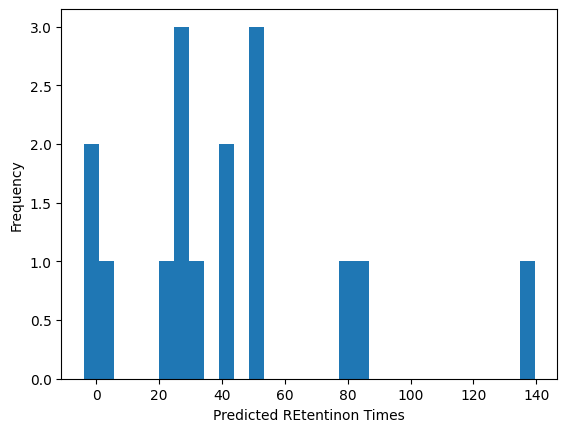

{'MATSRYEPVAEIGVGAYGTVYK': 51.6, 'ARDPHSGHFVALK': 32.1, 'VTLVFEHVDQDLRTYLDK': 52.1, 'APPPGLPAETIK': 29.1, 'DLMRQFLRGLDFLHANCIVHRDLK': 85.9, 'PENILVTSGGTVK': 28.3, 'PLFCGNSEADQLGK': 28.2, 'RISAFRALQHSYLHK': 49.3, 'AEERHK': 2.5, 'AGRSEEAVRWGARARK': 23.9, 'MVIEWERPRMILSNTTAVTPFLTK': 82.0, 'LWQETVQQGGNMSGLARRSPRSGDGK': 39.2, 'LEHSNDPFNVYIESNAWQEK': 42.6}


In [20]:
pooled_peptides_list = [pep for peptides in peptides.values() for pep in peptides]

print(pooled_peptides_list)
print(len(pooled_peptides_list))

retention_times = ms.predict_lc_retention_times(pooled_peptides_list)
print(retention_times)

visualisation_times = ms.plot_retention_time(retention_times.values())
selected_peptides = ms.select_retention_time_window(retention_times, lower_ret_time=2, upper_ret_time=100)

print(selected_peptides)

# 📊 Mass Spectrometry

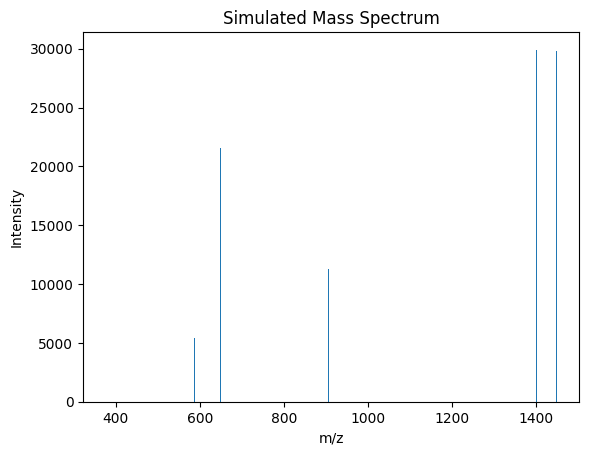

['M', 'MA', 'MAT', 'MATS', 'ATSR', 'TSR', 'SR', 'R']

In [23]:
mol_mass_collection = ms.calculate_mol_mass_collection(selected_peptides, ms.amino_acid_mass_dalton)
mz_collection = ms.calculate_mz_collection(mol_mass_collection, charge=2)

ms.plot_spectrum(mz_collection)

sample_peptide = "MATSR"
fragments = ms.fragment_peptide(sample_peptide)
fragments

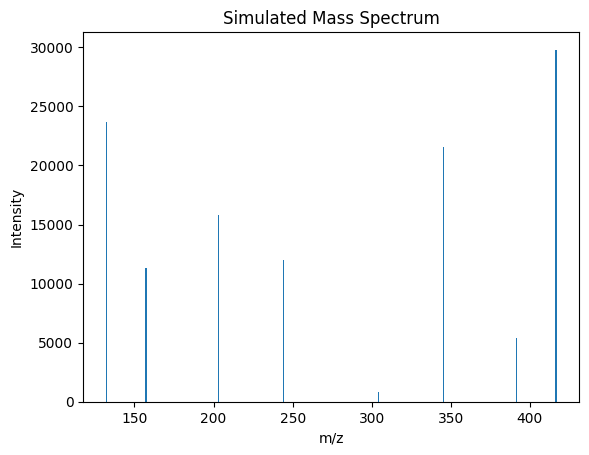

In [25]:
fragment_masses_ms2 = ms.calculate_mol_mass_collection(fragments, ms.amino_acid_mass_dalton)
fragment_mz2_collection = ms.calculate_mz_collection(fragment_masses_ms2, 1)

ms.plot_spectrum(fragment_mz2_collection)